# <a href="https://thetahat.ru/courses/ad">Введение в анализ данных</a>
## Домашнее задание 1. Простой анализ данных.


### Ссылки на использование ИИ

**Задача 1**
1. https://chat.deepseek.com/share/wox2eiy8m5e43dyv7p
    - разобраться в библиотеках matplotlib, seaborn, plotly
    - разобраться, когда какой вид графика применять
    - что такое недообучение, переобучение (при разных k в kNN algorithm)


### ИМПОРТЫ

In [1]:
import plotly.graph_objects as go
import plotly.express as px

import matplotlib.pyplot as plt
import seaborn as sns

import numpy as np

import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler

from collections import Counter

---

### Задача 1.

#### 0. Подготовка данных

Титаник был крупнейшим пассажирским судном в 1912—1913 годах. Во время первого рейса затонул в северной Атлантике, столкнувшись с айсбергом в ночь с 14 на 15 апреля 1912 года, при этом погибло 1502 из 2224 пассажиров и членов экипажа. Данные о пассажирах были собраны в таблицы, которые можно скачать с <a href="https://www.kaggle.com/c/titanic/data" target="_blank">Kaggle</a>. Эти данные часто используются в качестве обучающих в анализе данных.


Загрузите данные с помощью `pandas`.

Данные о библиотеке pandas, все методы взяты из семинарскийх конспектов по курсу Python2025 весна:
https://colab.research.google.com/drive/16loY-k7IY4YZyq11JVFxYQaKLmC_WpCM#scrollTo=1fn7GSsnYdfV

In [2]:
import pandas as pd
titanic = pd.read_csv("~/Downloads/titanic/train.csv")
titanic.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Для лучшего понимания процесса работы с данными, уточним ключевые термины.

> **Объект** — это единица данных, представленная набором признаков и используемая для обучения или предсказаний модели. В данной задаче являются пассажиры, им соответствуют *строки* таблицы данных.
>
> **Признаки (features)** — это характеристики, которые описывают объекты в данных. В таблицах данных они обычно соответствуют *колонкам*. В данной задаче мы будем работать со следующими признаками
>
> * `Pclass` — класс билета (1 = первый класс, 2 = второй класс, 3 = третий класс);
>
> * `Age` — возраст пассажира;
>
> * `Sex` — пол пассажира;
>
> * `SibSp` — количество братьев, сестер или супругов на борту;
>
> * `Parch` — количество родителей или детей на борту;
>
> * `Fare` — стоимость билета.
>
> **Таргет (target)** — это целевая переменная, которую мы хотим предсказать. В данной задаче мы будем предсказывать `Survived` — бинарная переменная, указывающая, выжил ли пассажир (1) или нет (0). Значения этой переменной имеются для обучающего набора данных, а для тестого — нет.

Из каждой части оставим несколько признаков, с которыми мы будем работать, а также отдельно &mdash; целевой признак, который мы хотим предсказать.

In [3]:
features_columns = ["Pclass", "Age", "Sex", "SibSp", "Parch", "Fare"]
target_column = "Survived"  # Целевой признак

X, y = titanic[features_columns], titanic[target_column]
X.head()

,Pclass,Age,Sex,SibSp,Parch,Fare
0,3,22.0,male,1,0,7.2500
1,1,38.0,female,1,0,71.2833
2,3,26.0,female,0,0,7.9250
3,1,35.0,female,1,0,53.1000
4,3,35.0,male,0,0,8.0500


В данных могут присутствовать пропуски. Пока что мы не умеем с ними работать, так что исключим из данных.

Посмотрите, сколько объектов имеют хотя бы один пропуск. Удалите их из данных.

Посмотрим сколько данных имеют пропуски:

In [4]:
print(f"Кол-во строк таблицы {len(X)}\n")
print(X.info())

Кол-во строк таблицы 891

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Pclass  891 non-null    int64  
 1   Age     714 non-null    float64
 2   Sex     891 non-null    str    
 3   SibSp   891 non-null    int64  
 4   Parch   891 non-null    int64  
 5   Fare    891 non-null    float64
dtypes: float64(2), int64(3), str(1)
memory usage: 46.0 KB
None


Как можно видеть всего 891 строка - метод len()\
Однако же в столбце Age - возраст, ненулевых ячеек всего лишь 714, значит есть 891 - 714 ячеек с Nan\
Удалим строки таблицы, содержащие NaN с помощью метода dropna()

In [5]:
X.isnull().sum()

Pclass      0
Age       177
Sex         0
SibSp       0
Parch       0
Fare        0
dtype: int64

Нулевые ячейки нашлись только в Age (из всех наших features_columns признаков), нулевых ячейк в столбце Age = 177 штук, удаляем!

In [6]:
X = X.dropna()
y = y.loc[X.index] # синхронизируем y, X же уменьшился

Разделите данные по строкам на две части случайным образом в соотношении 7:3. Первую часть мы будем называть *обучающей*, а вторую &mdash; *тестовой*.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, train_size=0.7, random_state=42   # число 42 любят программисты
    # а вообще любое число можно, а можно и не указывать, но тогда шафлиться, какие конкретно test_size штук пойдут под тестовый данные, а какие под обучающиеся на разных устройствах / в разные сессии работы будет по-разному
)
# train_size + test_size = 1.0 (100% of data)

#### 1. Исследование

> &#x2757; **Внимание.** Эта часть задачи должна выполняться *исключительно на обучающих данных*. За использование тестовых данных решение не будет оценено.

Проведите визуальный анализ данных чтобы понять, как различные признаки влияют на целевой. Исследовать можно не целиком обучающие данные, а разделить их на две части по одному из признаков, а далее рассматривать каждую часть отдельно.

*Не забывайте про информативность и эстетичность графиков, посмотрите презентацию про оформление домашних заданий.*

# СВЯЗЬ СМЕРТНОСТИ И КЛАССА БИЛЕТА

In [8]:
dead = X_train[y_train == 0].copy()
death_counts = dead['Pclass'].value_counts()
death_counts_data_frame = death_counts.reset_index()
death_counts_data_frame.columns = ['Pclass', 'Died_Cnt']
death_counts_data_frame = death_counts_data_frame.sort_values('Pclass')

total_deaths = death_counts_data_frame['Died_Cnt'].sum()
total_row = pd.DataFrame({'Pclass': [0], 'Died_Cnt': [total_deaths]})
# параметр Pclass = 0 добавлен искусствен и означает общее число погибших

death_counts_with_total = pd.concat([death_counts_data_frame, total_row], ignore_index=True)

fig = px.bar(death_counts_with_total,
             x = 'Pclass',
             y = 'Died_Cnt',
             labels = {'Pclass': 'Класс Билета', 'Died_Cnt': 'Кол-во умерших'},
             title = 'Кол-во не выживших людей по классам билетов',
             color = 'Pclass',
             color_continuous_scale = 'Blues'
             )
fig.add_annotation(
    x = 0,  # позиция по x (0 = Всего)
    y = death_counts_with_total[death_counts_with_total['Pclass']==0]['Died_Cnt'].values[0],
    text = "0 = общее число погибших<br>(добавлено искусственно)",
    showarrow = True,
    arrowhead = 1,
    ax = 40,
    ay = -40,
    font = dict(size=10, color="black"),
    bgcolor = "white"
)

fig.update_layout(height = 500, width = 1200,
                  xaxis_tickangle = -45,
                  )
fig.show()

* На графике изображено кол-во погиших людей, имеющих разный класс билета, класс билета = 0 - это искусственно добавленный столбец для демонстрации общего кол-ва погибших людей.
* Видно, что всего погибших было около 300. При наведении на другие столбцы можно увидеть, что около 180 человек имели билет 3 класса. Следовательно, ~300/180 ~= 1,6, то есть почти половина погибших имели ТРЕТИЙ класс билета => это первый признак по которому мы будем предсказывать (обучать модель)

Попробуем немного углубиться и понять, сколько погибших / выживших имели одинаковый класс билета

In [9]:
X_train_pclass = X_train.copy()

pclass_data_frame = pd.crosstab(X_train_pclass['Pclass'], y_train)
pclass_data_frame.columns = ['Погиб', 'Выжил']
pclass_data_frame = pclass_data_frame.reset_index()

fig = px.bar(pclass_data_frame,
             x = 'Pclass',
             y = ['Погиб', 'Выжил'],
             title = 'Влияние класса билета на выживаемость',
             labels={'Pclass': 'Класс билета', 'variable': 'Статус'},
             color_discrete_map = {'Погиб': 'darkblue', 'Выжил': 'pink'},
             barmode = 'group')

fig.update_layout(height = 800,
                  width = 800,
                  paper_bgcolor = 'white',
                  plot_bgcolor = 'white',
                  font = dict(size=10, color="black")
                  )
fig.show()

* На графике изображено для каждого класса билета: кол-во людей имевших этот класс билета - умерших и выживших
* При наведении на каждую колнку, можно увидеть цифры (именно кол-во людей в той или иной категории, соответсвующей легенде).
* Обратим внимание на 3й класс билета: кол-во выживших (value） = 58, кол-во погибших (value） синего столбца = 183 => в 1 /3 случаев люди умирали имея билет 3 класс.
* Неплохой опознавательный признак (для начала) для обучения модели - иметь 3 класс билета -> есть вероятность, что человек не выжил.


# Распределения по ПОЛУ умерших

Поймем еще как пол и кол-во умерших связаны между собой:

In [10]:
dead = X_train[y_train == 0].copy()
death_counts = dead['Sex'].value_counts()
death_counts_data_frame = death_counts.reset_index()
death_counts_data_frame.columns = ['Sex', 'Died_Cnt']
death_counts_data_frame = death_counts_data_frame.sort_values('Sex')

fig = px.pie(death_counts_data_frame,
             values = 'Died_Cnt',                                     # Значения, которые будут отображены как размер секторов (население)
             hole = 0.4,                                              # Добавляем «дырку» в центре диаграммы
             names = 'Sex',
             title = 'Процентное соотношение умерших по половому признаку',
             color = 'Sex',
             color_discrete_map={
                 "male" : 'lightblue',
                 "female" : 'lightpink'
             },
             labels={                                               # Подписи для осей и дополнительных данных
                 'Died_Cnt': 'Кол-во Погибших',
             },
             width = 1000,
             height = 1000
)

fig.show()

* На графике изображено, процентное соотношение умерших людей по половому признаку
* Очевидно из pie-диаграммы, что количество умерших мужчин больше, чем количество умерших женщин
* То есть мужчины умирали чаще, чем женщины.
* Из предыдущих графиков мы помним, что люди, имевшие 3 класс билета умирали достаточно часто.
* А что если объединить эти 2 признака: "мужчина" и "иметь 3 класс билета"? Вероятно, мы тогда, сможем сделать качественные выводы, которые пригодятся для обучения модели.

# ТЕПЕРЬ ОБЪЕДИНИМ ЭТИ ДВА ПРИЗНАКА

In [11]:
sex_pclass = X_train.copy()
sex_pclass['Survived'] = ['Погиб' if x == 0 else 'Выжил' for x in y_train]

# Добавляем небольшой "шум" (noise) чтобы точки не накладывались друг на друга
np.random.seed(42)
sex_pclass['Pclass_noise'] = sex_pclass['Pclass'] + np.random.normal(0, 0.1, len(sex_pclass))
sex_pclass['Sex_noise'] = np.where(sex_pclass['Sex'] == 'male', 0, 1) + np.random.normal(0, 0.05, len(sex_pclass))

fig = px.scatter(sex_pclass,
                 x = 'Sex_noise',
                 y = 'Pclass_noise',
                 color = 'Survived',
                 title = 'Пассажиры Титаника: Пол vs Класс (цвет = выживаемость)',
                 color_discrete_map = {'Погиб': 'darkblue', 'Выжил': 'pink'},
                 labels = {
                     'Sex_noise': 'Пол',
                     'Pclass_noise': 'Класс билета',
                     'Survived': 'Статус'
                 },
                 width = 800,
                 height = 800
)

fig.update_layout(paper_bgcolor = 'white', plot_bgcolor =' white', font = dict(size=10, color="black"))

fig.update_xaxes(
    tickvals = [0, 1],
    ticktext = ['Мужчины', 'Женщины']
)
fig.update_yaxes(
    tickvals = [1, 2, 3],
    ticktext = ['1 класс', '2 класс', '3 класс']
)

fig.show()

Из этого графика видно, что: $$\newline$$
*ЖЕНЩИНЫ*
1. Женщина с билетом 1ого класса с очень большой вероятностью выжила
2. Женщина с билетом 2ого класса скорее всего выжила
3. Женщина из 3го класса с вероятность ~2/3 выжила
$$\newline$$

*МУЖЧИНЫ*
1. Мужчина с билетом 1го класса с вероятностью 1/2 выжил:
2. Мужчина с билетом 2го класса с вероятностью 1/3 выжил:
3. Мужчина с билетом 3го класса с очень маленькой вероятностью выжил (скорее всего умер)

$$\newline$$
Вырисовывается более четкая картина того, как можно предсказывать выживаемость. Пока что у нас только два признака - пол, класс билета. Попробуем добавить еще третий признак - размер семьи

# ВЛИЯНИЕ РАЗМЕРА СЕМЬИ НА ВЫЖИВАЕМОСТЬ

In [12]:
X_train_fam = X_train.copy()
X_train_fam['FamilySize'] = 1 + X_train['Parch'] + X_train['SibSp']  # +1 сам пассажир

family_data_frame = pd.crosstab(X_train_fam['FamilySize'], y_train)
family_data_frame.columns = ['Погиб', 'Выжил']
family_data_frame = family_data_frame.reset_index()

fig = px.bar(family_data_frame,
             x='FamilySize',
             y=['Погиб', 'Выжил'],
             title='Влияние размера семьи на выживаемость',
             labels={'value': 'Количество людей', 'FamilySize': 'Размер семьи', 'variable': 'Статус'},
             color_discrete_map={'Погиб': 'darkblue', 'Выжил': 'pink'},
             barmode='group')

fig.update_layout(height=800,
                  width=800,
                  paper_bgcolor='white',
                  plot_bgcolor='white',
                  font=dict(size=10, color="black"))
fig.show()

* На графике изображено кол-во людей по категориям (Выжил / Погиб), которые имели конкретный размер семьи
* Видно, что, если размер семьи = 1 или размер семьи $\geq 5$ -> с большой веротностью человек умер\
Обозначим за множество А = {1, 5, 6, 7, 8}  (=1 или  $\geq 5$)
* Будем при неоднозначности предыдущего анализа (по половому признаку и классу билета) пользоваться дополнительно размером семьи (а точнее попаданием размера семьи в множество А), и, отталкиваясь, от этого наша модель будет предсказывать, выжил или погиб конкретный человек из тестовой выборки

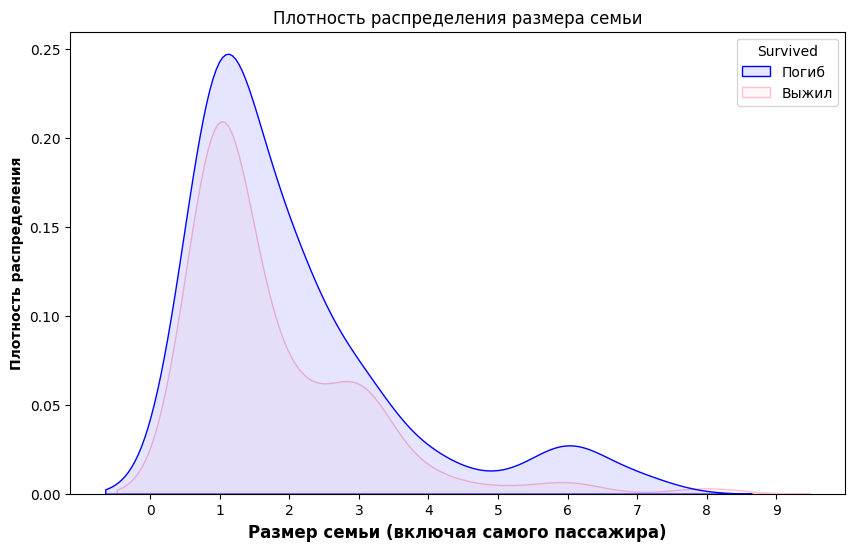

In [13]:
X_train_fam = X_train.copy()
X_train_fam['FamilySize'] = 1 + X_train['Parch'] + X_train['SibSp']  # +1 сам пассажир
X_train_fam = X_train_fam.reset_index()
X_train_fam['Survived'] = pd.Series(
                                    np.where(y_train == 0, "Погиб", "Выжил"),
                                    index = y_train.index
                                    )

plt.figure(figsize = (10, 6))
sns.kdeplot(data = X_train_fam,
            x = "FamilySize",
            hue = "Survived",
            fill = True,
            alpha = 0.1,
            palette = {'Погиб': 'blue', 'Выжил': 'pink'})
plt.title("Плотность распределения размера семьи")

plt.xlabel('Размер семьи (включая самого пассажира)', fontsize = 12, fontweight = 'bold')
plt.xticks(ticks = range(0, 10),
           labels = range(0, 10),
           fontsize = 10)
plt.ylabel('Плотность распределения', fontsize = 10, fontweight='bold')
plt.show()

* Этот график немного под другим углом анализирует ситуацию с размером семьи.
* Можно пронаблюдать, что типичный размер семьи среди пассажиров титаника (как погибших, так и выживших) $\in {1, 2, 3}$.
* Так же можно пронаблюдать, что если у человека размер семьи = 6, то он с большей вероятностью умер.
* График был по большей части создан, ради того, чтобы рассмотреть дополнительные возможности matplotlib.

#### 2. Классификация логическими правилами

На основе выше проведенного исследования предложите два разных правила вида
> 1). *если признак $x_1 > 5$, то класс 0, иначе посмотрим на признак $x_2$ и ...*
>
> 2). *если $x_1 > 5$ и $x_2 < 2$, то класс 1, иначе ...*

В совокупности используйте не менее трех различных признаков. Никакие статистические методы использовать не требуется, только логику и графики. Любые решения "из коробки" использовать запрещено. Например, достаточно пояснения "*по графику <описание графика> визуально я увидел, что при X > 100 большинство пассажиров выжило, поэтому использую правило <описание правила>*".


**Правило 1:**
пол и класс билета (график 3)

**Правило 2:**
размер семьи для доп верификации нашего предсказания
(график 4)

**Итоговый план предсказания**

1. Женщина из 1ого класса с очень большой вероятностью выжила -> отвечать будем да
2. Женщина из 2ого класса скорее всего выжила -> отвечать будем да
3. Женщина из 3го класса с вероятность 2/3 выжила -> отвечать будем да
4. Мужчина из 1го класса с вероятностью 1/2 выжил:\
    4.1. Если размер его семьи \in A -> отвечаем НЕТ (скорее всего умер)\
    4.2  Если размер его семьи \not in A -> отвечаем ДА (возможно выжил)
5. Мужчина из 2го класса с вероятностью 1/3 выжил:\
    5.1. Если размер его семьи \in A -> отвечаем НЕТ (скорее всего умер)\
    5.2  Если размер его семьи \not in A -> отвечаем ДА (возможно выжил)
6. Мужчина из 3го класса с очень маленькой вероятностью выжил ->  отвечаем НЕТ (скорее всего умер)

Реализуйте полученные логические правила по шаблону

In [14]:
def model(features: pd.DataFrame) -> pd.Series:
    """
    Предсказание целевого признака для данных features -- pandas-таблица данных.
    Возвращает pandas.Series с теми же индексами, что и у features.
    """
    # Создаем пустую Series с тем же индексом
    predicted = pd.Series(index=features.index, dtype=bool)

    family_size : int = features['SibSp'] + features['Parch'] + 1

    predicted = (
        (features['Sex'] == 'female') |
        (
            (features['Sex'] == 'male') &
            (features['Pclass'].isin([1, 2])) &
            (family_size.isin([1, 5, 6, 7, 8]))
        )
    )

    return predicted

Проверьте работоспособность данных моделей на тестовой выборке и оцените качество модели по метрике `accuracy`.

> &#x2755; *Примечание.* Полученные значения не влияют на оценку по заданию. Оценивается только корректность и обоснованность решения, а также графики и выводы.

In [15]:
def accuracy(target: pd.Series, predicted: pd.Series) -> float:
    """
    Вычисление критерия качества для предсказания predicted,
    если истинные значения -- target.
    Возвращает одно вещественное число.
    """
    accur : float = (predicted == target).sum()
    cnt : int = len(target)

    return accur / cnt * 100

y_predicted = model(X_test)
print(f"YOUR ACCURACY IS {accuracy(y_test, y_predicted):.2f}%\n")

YOUR ACCURACY IS 68.37%



# Попробуем чуть-чуть улучшить результат с помощью КОРРЕЛЯЦИЙ

Вдохновлено статьей на хабре (ссылка на статью была найдена на https://thetahat.ru/courses/design-hw). $$\newline$$
Сама статья: https://habr.com/ru/articles/984144/

<Axes: >

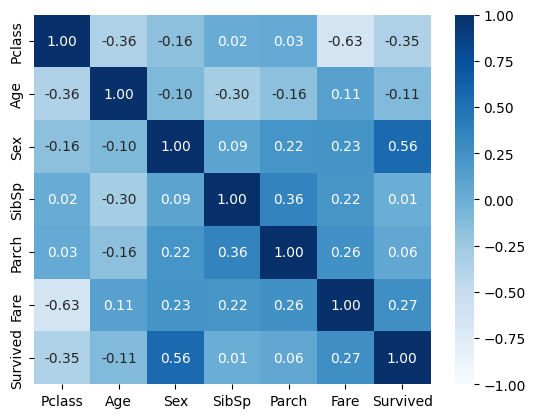

In [16]:
# сиборн наворачивает свои фичи поверх матплотлиба. УДИВИТЕЛЬНО! (то есть можно писать plt.figure(), seaborn - нечто, plt.show()

X_train['Sex'] = pd.Series(
                            np.where(X_train['Sex'] == 'male', 0, 1), # МУЖ - 0, ЖЕН - 1,
                            index = X_train.index
                            )
data_frame = X_train.copy()
data_frame['Survived'] = y_train

features_list = features_columns + [target_column]
corr_matrix = data_frame[features_list].corr() # .corr() функция пандас, считает попарную корреляцию
sns.heatmap(corr_matrix,
            cmap = 'Blues',
            vmin = -1, vmax = 1,
            annot = True,     # Пишем значения внутри ячеек
            fmt = ".2f"       # Формат чисел (2 знака после запятой)
            )

* На графике изображена матрица попарных корреляций всех признаков из features_column (признаков, которые мы рассматриваем)
* ВЫВОД: Sex не влияет на все остальные параметры, даже на Survived. С точки зрения математики. Хотя, возможно, с точки зрения предыдущего анализа видно, что статистически погибло больше мужчин, это же хорошо сочетается с исторической составляющей трагедии.
* Видно, что коррелируют с Survived (то есть значения зависят друг от друга): Fare (0,26 коэф корреляции), Pclass (-0.35), хотя так же видно что Pclass и Fare имееют около -0,63 коэф, как можно было предположить по смыслу они очень зависимы.
Отметим также, что Fare + Age коэффициент 0,11 - небольшая связь есть, по этим двум признакам можно поробовать построить ScatterPlot с легендой выжил/погиб и по ним пробовать предсказывать

Стремимся проанализировать Fare + Age.\
Для начала прросто попробуем поработать с возрастом


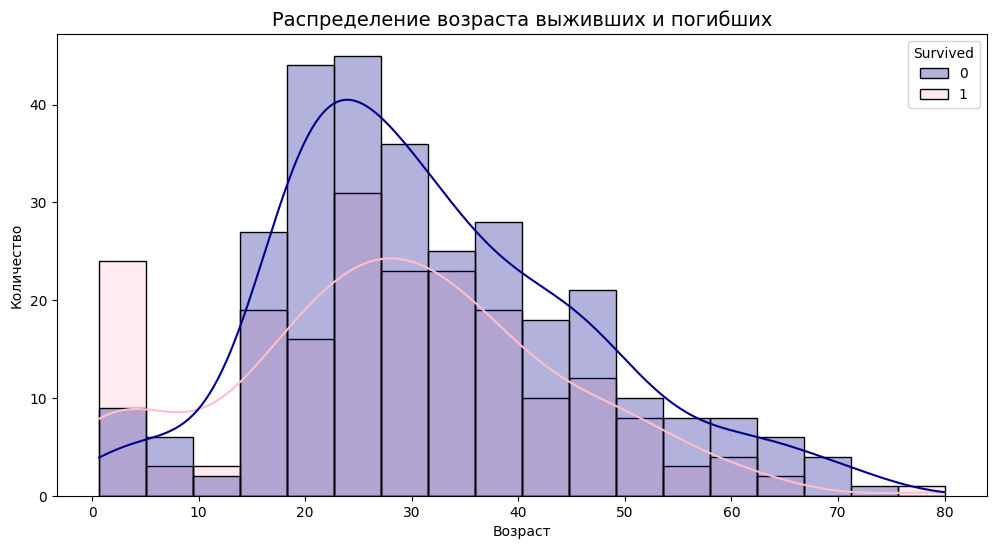

In [17]:
plt.figure(figsize = (12, 6))
sns.histplot(data = data_frame,
             x = 'Age',
             hue = 'Survived',
             bins = 'auto',  # bins - кол-во столбцов на гистограмме
             kde = True,     # (Kernel Density Estimation) добавляет линию плотности распределения
             alpha = 0.3,    # прозрачность
             palette = ['darkblue', 'pink'])
plt.title('Распределение возраста выживших и погибших', fontsize = 14)
plt.xlabel('Возраст')
plt.ylabel('Количество')
plt.show()

* На графике изображено распределение людей по категориям (Погибли / Выжили) и по возрасту.
* Видно, что дети возраста $\leq$ 15, выживали чаще, чем умирали.
* А так же видно, что люди возраста $\in$ [67, 75] умирали, а люди возраста $\geq$ 76 выжили.
* Пока что не очень информативно. Но с этим можно работать для обучения модели.

Попробуем посмотреть на цену билета и выживаемость

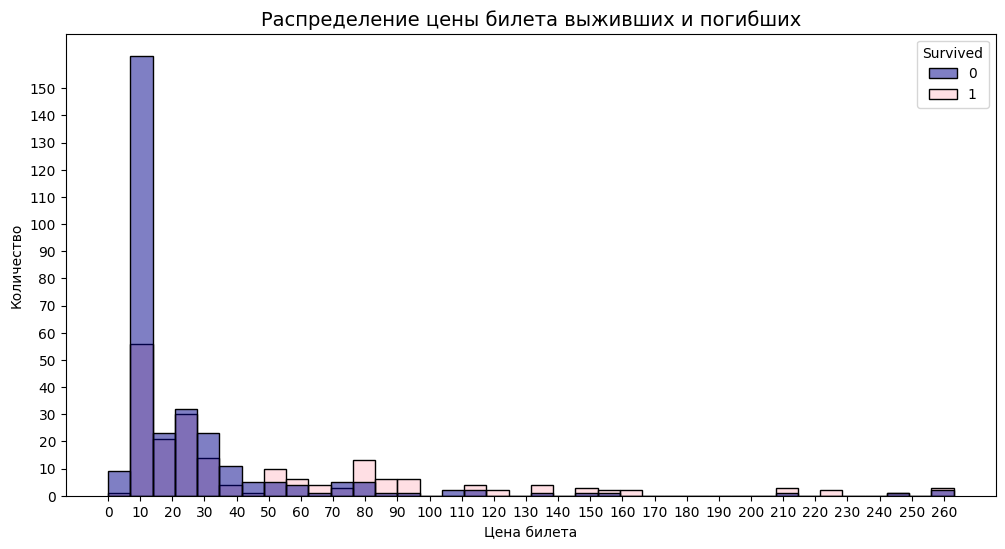

In [18]:
plt.figure(figsize = (12, 6))
sns.histplot(data = data_frame,
             x = 'Fare',
             hue = 'Survived',
             bins = 'auto',  # bins - кол-во столбцов на гистограмме
             kde = False,    # (Kernel Density Estimation) добавляет линию плотности распределения
             alpha = 0.5,
             palette = ['darkblue', 'pink']
             )
plt.title('Распределение цены билета выживших и погибших', fontsize = 14)
plt.xlabel('Цена билета')
plt.ylabel('Количество')

plt.xticks(np.arange(0, 270, 10))
plt.yticks(np.arange(0, 160, 10))
plt.show()


* На графике изображено распределение людей по категориям (Погибли / Выжили) и по возрасту.
* Видно: если люди имели цену билета $\in (118, 130)$ или $\in (160, 170)$ или $\in (220, 230)$ -> они выжили, если цена их билета была $\in$ (240, 250) -> умерли\
* Теперь, наконец, вооружившись знаниями последних двух графиков, построим ScatterPlot, по двум признак сразу и Age, и Fare, который потом мы объединим с уже имеющимся анализом по половому признаку, размеру семьи и классу билета:

<Figure size 2500x1500 with 0 Axes>

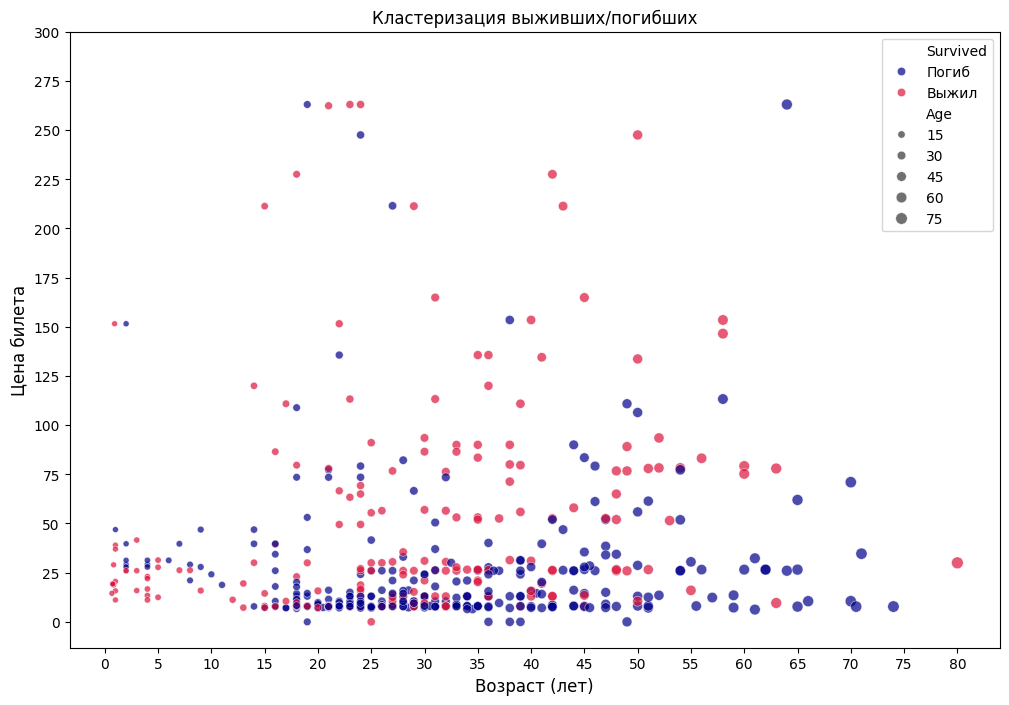

In [19]:
data_frame = X_train.copy()
data_frame['Survived'] = pd.Series(
                                    np.where(y_train == 1, 'Выжил', 'Погиб'),
                                    index = X_train.index
                                 )

plt.figure(figsize=(25, 15))

fig, ax = plt.subplots(figsize = (12, 8))
ax.set_facecolor('white')         # фон самого графика

sns.scatterplot(
    data = data_frame,
    x = "Age",
    y = "Fare",
    hue = "Survived",       # 3-е измерение: цвет по виду
    size = "Age",           # 4-е измерение: размер точки по возрасту
    alpha = 0.7,
    palette = ["darkblue", "crimson"],
    ax = ax
)

plt.title("Кластеризация выживших/погибших")

plt.xlabel("Возраст (лет)", fontsize = 12)
plt.ylabel("Цена билета", fontsize = 12)

plt.xticks(np.arange(0, 81, 5))
plt.yticks(np.arange(0, 301, 25))

plt.show()

На графике можно выделить группы людей:
1. Дети возраста <= 6, чья цена билета была <= 25 -> они выживали (как можно видеть в прямоугольнике [0, 6] x [0, 25] - точки малинового цвета
2. Пожилые люди возраста >= 78 -> одна малиноая точка -> человек выжил
3. Люди среднего возраста $\in [30, 48]$, у кого цена билета больше восьми -> прямоугольник [30, 48] x [100, 275] имеет всего лишь 1 синюю точку, а все остальные малиновые -> люди выживали
4. Рассмотрим людей среднего возраста $\in [33, 40]$, у кого были дешевые билеты цены $\leq$ 15 (как мы помним Pclass и Fare очень связаны), выходит что это люди 3го класса: -> люди умерли
5. Расмотрим подростков возраста $\in [10, 17]$, у кого цена билета >= 80: -> выжили (точки малиновые, кроме быть может одной синей)


Собираем все признаки вместе: пол, класс билета, цена билета, возраст, размер семьи и снова обучим модель.

In [20]:
def predict_using_my_algo(ans : dict) -> bool:
    #  ======== добавили из предыдущего графика
    if 118 < ans['Fare'] < 130 or 160 < ans['Fare'] < 170 or 220 < ans['Fare'] < 230:
        return True
    if 240 < ans['Fare'] < 250:
       return False
    # ======== добавили из этого графика (и стала чуть точнее модель)
    if (63 <= ans['Age'] <= 75):
        return False
    if (ans['Fare'] >= 100 and 30 <= ans['Age'] <= 48) or (ans['Age'] >= 78) or (ans['Age'] <= 6 and ans['Fare'] <= 25):
        return True
    if (10 <= ans['Age'] <= 17 and ans['Fare'] >= 80):
        return True
    if (33 <= ans['Age'] <= 40 and ans['Fare'] <= 15):
        return False
    # ======== это уже было
    if ans['Sex'] == 'female':
        return True
    elif ans['Sex'] == 'male':
        family_size : int = ans['SibSp'] + ans['Parch'] + 1
        if ans['Pclass'] == 1:
            return family_size in [1, 5, 6, 7, 8]
        elif ans['Pclass'] == 2:
            return family_size in [1, 5, 6, 7, 8]
        elif ans['Pclass'] == 3:
            return False

    # Аля рукописное решающее дерево из ML

def model(features: pd.DataFrame) -> pd.Series:
    """
    Предсказание целевого признака для данных features -- pandas-таблица данных.
    Возвращает pandas.Series с теми же индексами, что и у features.
    """
    # Создаем пустую Series с тем же индексом
    predicted = pd.Series(index=features.index, dtype=bool)

    for i in features.index:
        ans = {
            "Pclass" : 0,
            "Age" : 0,
            "Sex": '',
            "SibSp": 0,
            "Parch": 0,
            "Fare": 0
        }
        for f in features_columns:
            ans[f] = features[f][i]

        survived : bool = predict_using_my_algo(ans)
        predicted[i] = survived

    return predicted

def accuracy(target: pd.Series, predicted: pd.Series) -> float:
    """
    Вычисление критерия качества для предсказания predicted,
    если истинные значения -- target.
    Возвращает одно вещественное число.
    """
    accur : float = 0
    cnt : int = len(target)
    for i in target.index:
        accur += (predicted[i] == target[i])

    return accur / cnt * 100

y_predicted = model(X_test)
print(f"YOUR ACCURACY IS {accuracy(y_test, y_predicted):.2f}%\n")

YOUR ACCURACY IS 72.09%



Точность предсказаний модели после новой порции признаков стала выше: была 68.37%, стала 72.09%

#### 3. Классификация методом ближайшего соседа

> Почему можно использовать KNN?

**Ответ: ** датасет слишком маленьки, в нем всего 891 одна запись, что и по времени предсказаний, и по памяти для обучения это вполне приемлемо

В данной части задачи оставим только признаки `'Pclass'`, `'Age'`, `'Sex'`,`'Fare'`.


&#x2753; **Вопрос** &#x2753;
> Какие могли бы возникнуть проблемы при использовании признаков `'SibSp'`, `'Parch'`? Имеется ли подобная проблема для признака `'Pclass'`?

**Ваш ответ:** У каждого человека, теоретически могло бы быть одинаковое количество SibSp, Parch и было бы сложно отличить, тогда это не дало бы нам никакой информации. Либо же они мало отличаются. В то время как Pclass даже с точки зрения логики ситуации очень влиял на выживаемость, естественно, что людей из 3го класса (ближе к воде) погибло больше, чем из 1ого.

Признак `'Sex'` имеет два различных строковых значения. Чтобы использовать его в модели kNN, преобразуйте их в 0 и 1.

МУЖЧИНА - 0\
ЖЕНЩИНА - 1

In [21]:
X_train.drop(['SibSp', 'Parch'], axis = 1, inplace = True)
X_test.drop(['SibSp', 'Parch'], axis = 1, inplace = True)

X_train['Sex'] = pd.Series(
                            np.where(X_train['Sex'] == 'male', 0, 1),
                            index = X_train.index
                            )

X_test['Sex'] = pd.Series(
                            np.where(X_test['Sex'] == 'male', 0, 1),
                            index = X_test.index
                            )
X_train.head()

,Pclass,Age,Sex,Fare
37,3,21.0,1,8.0500
58,2,5.0,1,27.7500
57,3,28.5,1,7.2292
94,3,59.0,1,7.2500
209,1,40.0,1,31.0000


Постройте классификатор методом ближайшего соседа. Обучите его и оцените качество модели. Сравните с предыдущим методом.

Пока никаких других преобразований данных делать не нужно.

Попробуем улучшить результаты предсказаний, для этого надо сначала посмотреть на сами данные. Выведите значение минимального и максимального объекта для каждого признака.

In [22]:
for f in features_columns:
    if f not in ['SibSp', 'Parch']:
        print(f"=== для признака {f} ====")
        print(f"Минимальное значение = {X_train[f].min()}")
        print(f"Максимальное значение = {X_train[f].max()}")
        print("\n")

=== для признака Pclass ====
Минимальное значение = 1
Максимальное значение = 3


=== для признака Age ====
Минимальное значение = 0.67
Максимальное значение = 80.0


=== для признака Sex ====
Минимальное значение = 1
Максимальное значение = 1


=== для признака Fare ====
Минимальное значение = 0.0
Максимальное значение = 263.0




Как мы видим данные в каждом столбце распределены очень по-разному.

&#x2753; **Вопрос** &#x2753;
> Как это может повлиять на работу kNN, почему?

**Ваш ответ:**  не стоит проводить алгоритм kNN с точками из пространства R^d, где каждый признак \in R, при том, что данные рзаного масштаба, поскольку при подсчете любой метрики (Манхэтенской, Евклидовой или другой), порядок ответа будет зависеть только от той величины, у к-рой размах значений больше.
В нашем случае точки из R^6 (поскольку у нас 6 признаков) из них те, кто имеют больший диапазон значений: Fare, Age. Они повлияют на ответ, а все остальное не особо.
ИЛИ вспомним пример из лекции про киллометры (значения могут быть 1000, 5000) и киллограммы (могут быть 1, 2, 100) или наоборот, но на ответ здесь бы влияла только одна величина.
А мы хотим, чтобы предсказания производились наиболее точно, а значит хотим, чтобы каждый признак объекта давал вклад в расчёт метрики-расстояния.

Для решения этой проблемы нужно привести признаки к единому масштабу. Существует много методов масштабирования рассмотрим работу одного из них &mdash; **минимаксная нормализация**

  
> **Минимакс** &mdash; линейное преобразование данных в диапазоне $[0, 1]$, где минимальное и максимальное масштабируемые значения соответствуют 0 и 1 соответственно.
> Реализуется оно по следующей формуле:
>
> $$\widetilde{x}_{ij} = \frac{x_{ij} - m_j}{M_j - m_j}$$
>
> где $x_{ij}$ &mdash; значение признака $j$ для объекта $i$, а $m_j$ и $M_j$ &mdash; минимальное и максимальное значения признака $j$ в *обучающем* наборе данных.  
> В модуле `sklearn.preprocessing` есть [класс](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.MinMaxScaler.html) `MinMaxScaler`, который реализует эту операцию. Давайте рассмотрим методы этого класса подробнее:
>
> * `fit(X)`: вычисляет минимальные и максимальные значения для каждого признака.
>
> * `transform(X)`: применяет масштабирование к данным.
>
> * `fit_transform(X)`: объединяет оба метода, сначала подгоняя модель, а затем трансформируя данные.
>
> * `inverse_transform(X)`: восстанавливает исходные данные из масштабированных.
> 
> Обратите внимание, что методы `fit(X)` и `fit_transform(X)` можно применять только к обучающим данным.


Стоит отметить что существуют и другие методы масштабирования данных.

&#x2753; **Вопрос** &#x2753;
> В чем может быть недостаток такого метода масштабирования?

**Ваш ответ:** Данные могут стать трудно различимыми после применения MinMaxScaler, поскольку если в данных есть выброс (пусть это max значение), а все остальные данные на порядок меньше, то большая часть данных может скопиться в (0, 0.5) и станет очень трудно различимой, а выброс соответсвенно преобразуется в 1.0 = (x_max - x_min)/(x_max - x_min)\
Это если выброс это максимальное значение\
Пример: [1, 10, 100] -----MinMaxScaler----> [0.0, 0.1, 1]\
Если выброс это минимальное значение то смысл тот же, все значения преобразованные скапливаются в (0.5, 1)\
[1, 100, 101, 102] -----MinMaxScaler----> [0.0, 99/101 ~= 0.98,  0.99, 1]\
То есть данные становятся менее информативными - сложно различать.

Отмасштабируйте данные

In [23]:
new_scaler = MinMaxScaler()

X_train_scaled = X_train.copy()
X_train_scaled = new_scaler.fit_transform(X_train_scaled)  # fit-transform только на трэйне!
X_train_scaled = pd.DataFrame(
    X_train_scaled,
    columns=X_train.columns,
    index=X_train.index
)

X_test_scaled = X_test.copy()
X_test_scaled = new_scaler.transform(X_test_scaled) # на тесте только transform!
X_test_scaled = pd.DataFrame(
    X_test_scaled,
    columns=X_test.columns,
    index=X_test.index
)

X_test_scaled.head(10)

,Pclass,Age,Sex,Fare
149,0.5,0.520988,-1.0,0.049430
407,0.5,0.029371,-1.0,0.071293
53,0.5,0.357116,0.0,0.098859
369,0.0,0.294088,0.0,0.263498
818,1.0,0.533594,-1.0,0.024525
549,0.5,0.092399,-1.0,0.139734
85,1.0,0.407538,0.0,0.060266
774,0.5,0.672255,0.0,0.087452
100,1.0,0.344510,0.0,0.030022
816,1.0,0.281482,0.0,0.030133


Теперь выведите значения максимума и минимума нормализованных признаков. Обратите внимание `MinMaxScaler` возвращается объект в виде `np.ndarray`.

In [24]:
for f in features_columns:
    if f not in ['SibSp', 'Parch']:
        print(f"=== для признака {f} ====")
        print(f"Минимальное значение = {X_train_scaled[f].min()}")
        print(f"Максимальное значение = {X_train_scaled[f].max()}")
        print("\n")

=== для признака Pclass ====
Минимальное значение = 0.0
Максимальное значение = 1.0


=== для признака Age ====
Минимальное значение = 0.0
Максимальное значение = 1.0


=== для признака Sex ====
Минимальное значение = 0.0
Максимальное значение = 0.0


=== для признака Fare ====
Минимальное значение = 0.0
Максимальное значение = 1.0




Можно пронаблюдать, что при масштабировании данных: max Sex = min Sex = 0.0, и это очень хорошо согласуется с приведенной выше heatmap, из которой мы сделали вывод, что конкретно в наших данных пол человека играет не очень большую роль для предсказания: выжил / погиб, хотя стоит заметить, что все же в историческом контексте и в соответсвии с диагромой выше женщин умерло сильно меньше чем мужчин

Обучите модель и сравните результат предсказаний со стандартизацией и без.

С МАСШТАБИРОВАНИЕМ НО БЕЗ СТАНДРАТИЗАЦИИ

In [25]:
features_columns = ['Pclass', 'Age', 'Sex', 'Fare']

In [26]:
X_train = X_train.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)
X_train_scaled = X_train_scaled.reset_index(drop=True)
X_test_scaled = X_test_scaled.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)
y_test = y_test.reset_index(drop=True)
# синхронизируем данные между всеми таблицами и заодно приятный бонус эти индексы стали как в отсортированном массиве euclidian_distances

def predicting_using_Knn(ans_array : np.array, train_objects : pd.DataFrame, k : int) -> bool:
    # train_objects - это или X_train, или X_train_scaled
    euclidian_distances = np.sqrt(((train_objects - ans_array) ** 2).sum(axis=1)) # axis 1 - по столбу суммирует (то есть по одному признаку)

    k_nearest_indexes = np.argsort(euclidian_distances)[0:k]
    k_nearest_targets = y_train.iloc[k_nearest_indexes].values

    counter = Counter(k_nearest_targets)
    return bool(counter.most_common(1)[0][0])


def model_Knn(features: pd.DataFrame, train_objects: pd.DataFrame,  k : int = 2) -> pd.Series:
    """
    Предсказание целевого признака для данных features -- pandas-таблица данных.
    train_objects - это или X_train, или X_train_scaled или X_train_stand_scaled
    Возвращает pandas.Series с теми же индексами, что и у features.
    """
    # Создаем пустую Series с тем же индексом
    predicted = pd.Series(index=features.index, dtype=bool)

    for i in range(len(features)):
        ans_array = features[features_columns].iloc[i].values
        survived : bool = predicting_using_Knn(ans_array, train_objects, k)  # True - выжил, False - умер
        predicted[i] = survived

    return predicted

def accuracy(target: pd.Series, predicted: pd.Series) -> float:
    """
    Вычисление критерия качества для предсказания predicted,
    если истинные значения -- target.
    Возвращает одно вещественное число.
    """
    accur : float = (predicted == target).sum()
    cnt : int = len(target)
    return accur / cnt * 100

# Результат на отмасштабированных данных не стандартизированных
scaled_unstandardized_accuracy = []
for k in range(1, 20 + 1):
    y_predicted = model_Knn(X_test_scaled, X_train_scaled, k)
    print(f"k = {k},  YOUR ACCURACY on scaled data IS {accuracy(y_test, y_predicted):.2f}%\n")
    scaled_unstandardized_accuracy.append(accuracy(y_test, y_predicted))

k = 1,  YOUR ACCURACY on scaled data IS 64.65%

k = 2,  YOUR ACCURACY on scaled data IS 64.65%

k = 3,  YOUR ACCURACY on scaled data IS 63.72%

k = 4,  YOUR ACCURACY on scaled data IS 64.65%

k = 5,  YOUR ACCURACY on scaled data IS 64.65%

k = 6,  YOUR ACCURACY on scaled data IS 65.12%

k = 7,  YOUR ACCURACY on scaled data IS 67.44%

k = 8,  YOUR ACCURACY on scaled data IS 68.37%

k = 9,  YOUR ACCURACY on scaled data IS 66.05%

k = 10,  YOUR ACCURACY on scaled data IS 66.05%

k = 11,  YOUR ACCURACY on scaled data IS 65.58%

k = 12,  YOUR ACCURACY on scaled data IS 64.65%

k = 13,  YOUR ACCURACY on scaled data IS 67.44%

k = 14,  YOUR ACCURACY on scaled data IS 64.65%

k = 15,  YOUR ACCURACY on scaled data IS 66.98%

k = 16,  YOUR ACCURACY on scaled data IS 65.12%

k = 17,  YOUR ACCURACY on scaled data IS 68.37%

k = 18,  YOUR ACCURACY on scaled data IS 67.91%

k = 19,  YOUR ACCURACY on scaled data IS 68.37%

k = 20,  YOUR ACCURACY on scaled data IS 67.44%



**Вывод:** kNN algorithm на отмасштабированных данных VS "ручная if-else" модели $$\newline$$
kNN algorithm на отмасштабированных данных - это чисто математический расчёт, который ищет похожих пасажиров с помощью формулы,он не знает ни исторического контекста (на к-рый мы время от времени опирались при анализе графиков), он мог учитывать не все (Sex) точно не учитывал, потому что в отмасштабированных данных Sex_min = Sex_max = 0.0, а при анализе на графиках и построению нашей "ручной if-else" модели мы пол учитывали

In [27]:
# Результат на неотмасштабированных данных нестандартизированных
for k in range(1, 20+1):
    y_predicted = model_Knn(X_test, X_train, k)
    print(f"k = {k},  YOUR ACCURACY on unscaled data IS {accuracy(y_test, y_predicted):.2f}%\n")

k = 1,  YOUR ACCURACY on unscaled data IS 63.26%

k = 2,  YOUR ACCURACY on unscaled data IS 63.26%

k = 3,  YOUR ACCURACY on unscaled data IS 65.58%

k = 4,  YOUR ACCURACY on unscaled data IS 65.58%

k = 5,  YOUR ACCURACY on unscaled data IS 63.72%

k = 6,  YOUR ACCURACY on unscaled data IS 67.44%

k = 7,  YOUR ACCURACY on unscaled data IS 66.51%

k = 8,  YOUR ACCURACY on unscaled data IS 66.98%

k = 9,  YOUR ACCURACY on unscaled data IS 67.44%

k = 10,  YOUR ACCURACY on unscaled data IS 66.98%

k = 11,  YOUR ACCURACY on unscaled data IS 66.05%

k = 12,  YOUR ACCURACY on unscaled data IS 67.44%

k = 13,  YOUR ACCURACY on unscaled data IS 67.44%

k = 14,  YOUR ACCURACY on unscaled data IS 68.84%

k = 15,  YOUR ACCURACY on unscaled data IS 69.77%

k = 16,  YOUR ACCURACY on unscaled data IS 68.37%

k = 17,  YOUR ACCURACY on unscaled data IS 68.37%

k = 18,  YOUR ACCURACY on unscaled data IS 69.77%

k = 19,  YOUR ACCURACY on unscaled data IS 69.77%

k = 20,  YOUR ACCURACY on unscaled data 

**Вывод:** kNN algorithm на отмасштабированных данных VS kNN algorithm на НЕотмасштабированных данных $$\newline$$
На неотмасштабированных данных результат немного отличается:
  * **k = 1**: scaled data - 71.16%, unscaled - 67.91%
  * **k = 2**: scaled data - 71.16%, unscaled - 67.91%
  * **начиная с k=1 на масштабированных данных процент правильных ответов больше: УТВерждение**
  * **k = 7**: scaled data - 76.28%, unscaled - 66.51%
  * **k = 19**: scaled data - 73.95%, unscaled - 70.23%  $$\newline$$
  **Из утверждения ясно, что масштабирование отработало так как от него ожидалось**. Сейчас явно можно видеть тот эффект, про который мы говорили как только ввели масштабирование: почему хуже на немасштабированных данных? потому что в немасштабированных данных, по факту, учитывается только Fare, поскольку у него диапазон значений самый большой из диапазона значений всех остальных признаков. У остальных признаков значения на порядок меньше и они как бы уходят в о-малое (потому что при подсчете Евклидова расстояния Pclass - Pclass $\in [0, 3]$. А на преобразованных данных все параметры учитываются одинаково (мы их отмасштабировали - больше не сравниваем "килограммы с киллометрами").

ТЕПЕРЬ К МАСШТАБИРОВАНИЮ ДОБАВИМ ЕЩЕ СТАНДАРТИЗАЦИЮ

In [28]:
scaler = StandardScaler()
min_max_scaler = MinMaxScaler()

scaler.fit(X_train)
X_train_standard = scaler.transform(X_train)
X_test_standard = scaler.transform(X_test)

# Преобразуем обратно в DataFrame (потому что после transform() данные стали numpy.ndarray)
X_train_standard = pd.DataFrame(
    X_train_standard,
    columns = X_train.columns,
    index = X_train.index
)

X_test_standard = pd.DataFrame(
    X_test_standard,
    columns = X_test.columns,
    index = X_test.index
)

min_max_scaler.fit(X_train_standard)
X_train_stand_scaled = min_max_scaler.transform(X_train_standard)
X_test_stand_scaled = min_max_scaler.transform(X_test_standard)

X_train_stand_scaled = pd.DataFrame(
    X_train_stand_scaled,
    columns = X_train.columns,
    index = X_train.index
)

X_test_stand_scaled = pd.DataFrame(
    X_test_stand_scaled,
    columns = X_test.columns,
    index = X_test.index
)

Сначала с помощью стандартизации сделали среднее = 0, дисперсию = 1\
Затем с помощью Min_Max_Scaler - отнормировали / отмасштабировали, чтобы все значения были $\in [0, 1]$

In [29]:
# Результат на отмасштабированных и стандартизированных данных
scaled_standardized_accuracy = []
for k in range(1, 20 + 1):
    y_predicted = model_Knn(X_test_stand_scaled, X_train_stand_scaled, k)
    print(f"k = {k},  YOUR ACCURACY on scaled data IS {accuracy(y_test, y_predicted):.2f}%\n")
    scaled_standardized_accuracy.append(accuracy(y_test, y_predicted))

k = 1,  YOUR ACCURACY on scaled data IS 64.65%

k = 2,  YOUR ACCURACY on scaled data IS 64.65%

k = 3,  YOUR ACCURACY on scaled data IS 63.72%

k = 4,  YOUR ACCURACY on scaled data IS 64.65%

k = 5,  YOUR ACCURACY on scaled data IS 64.65%

k = 6,  YOUR ACCURACY on scaled data IS 65.12%

k = 7,  YOUR ACCURACY on scaled data IS 67.44%

k = 8,  YOUR ACCURACY on scaled data IS 68.37%

k = 9,  YOUR ACCURACY on scaled data IS 66.05%

k = 10,  YOUR ACCURACY on scaled data IS 66.05%

k = 11,  YOUR ACCURACY on scaled data IS 65.12%

k = 12,  YOUR ACCURACY on scaled data IS 64.65%

k = 13,  YOUR ACCURACY on scaled data IS 67.44%

k = 14,  YOUR ACCURACY on scaled data IS 64.65%

k = 15,  YOUR ACCURACY on scaled data IS 66.98%

k = 16,  YOUR ACCURACY on scaled data IS 65.12%

k = 17,  YOUR ACCURACY on scaled data IS 68.37%

k = 18,  YOUR ACCURACY on scaled data IS 67.91%

k = 19,  YOUR ACCURACY on scaled data IS 68.37%

k = 20,  YOUR ACCURACY on scaled data IS 67.44%



In [30]:
print("       МАСШТАБИРОВ-Е и НЕСТАНДАРТ-Е |МАСШТАБИРОВ-Е и СТАНДАРТ-Е данные (результаты accuracy работы knn при разных k)")
for k in range(1, 20 + 1):
    comment : str = ""
    if scaled_unstandardized_accuracy[k - 1] < scaled_standardized_accuracy[k - 1]:
        comment = "<-----  Стандартизированные победили"
    elif scaled_unstandardized_accuracy[k - 1] == scaled_standardized_accuracy[k - 1]:
        comment = "<-----  Одинаково"
    print(f"k = {k}: {scaled_unstandardized_accuracy[k - 1]:.2f}%       |       {scaled_standardized_accuracy[k - 1]:.2f}%  {comment}")

       МАСШТАБИРОВ-Е и НЕСТАНДАРТ-Е |МАСШТАБИРОВ-Е и СТАНДАРТ-Е данные (результаты accuracy работы knn при разных k)
k = 1: 64.65%       |       64.65%  <-----  Одинаково
k = 2: 64.65%       |       64.65%  <-----  Одинаково
k = 3: 63.72%       |       63.72%  <-----  Одинаково
k = 4: 64.65%       |       64.65%  <-----  Одинаково
k = 5: 64.65%       |       64.65%  <-----  Одинаково
k = 6: 65.12%       |       65.12%  <-----  Одинаково
k = 7: 67.44%       |       67.44%  <-----  Одинаково
k = 8: 68.37%       |       68.37%  <-----  Одинаково
k = 9: 66.05%       |       66.05%  <-----  Одинаково
k = 10: 66.05%       |       66.05%  <-----  Одинаково
k = 11: 65.58%       |       65.12%  
k = 12: 64.65%       |       64.65%  <-----  Одинаково
k = 13: 67.44%       |       67.44%  <-----  Одинаково
k = 14: 64.65%       |       64.65%  <-----  Одинаково
k = 15: 66.98%       |       66.98%  <-----  Одинаково
k = 16: 65.12%       |       65.12%  <-----  Одинаково
k = 17: 68.37%       |       

**Вывод:** kNN algorithm на отмасштабированных данных\
БЕЗ стандартизации VS СО стандартизацией $$\newline$$
* Как видно из выводов принта, стандартизация улучшает точность алгоритма kNN
* Нестандартизированные данные оптимально при k $\in {6, 7, 9, 11}$
* При остальных k (16 штук значений) стандартизированные данные дают лучший результат

**А можем ли мы как-то еще повысить точность модели?**

Как мы видели, параметр $k$ числа соседей является необучаемым т.е. гиперпараметром, который выставляется вручную. Выбор оптимального значения $k$ важен, так как слишком маленькое значение может привести к переобучению, а слишком большое — к недообучению.



Постройте графики зависимостей точности (`accuracy_score`) от значения $k$ (от 1 до 20) для обучающей и тестовой выборок, на одной фигуре должно быть нарисовано две зависимости.

Делаем на отмасштабированных данных СО стандартизации, потому что как мы поняли выше, точность предсказаний лучше именно в этом случае

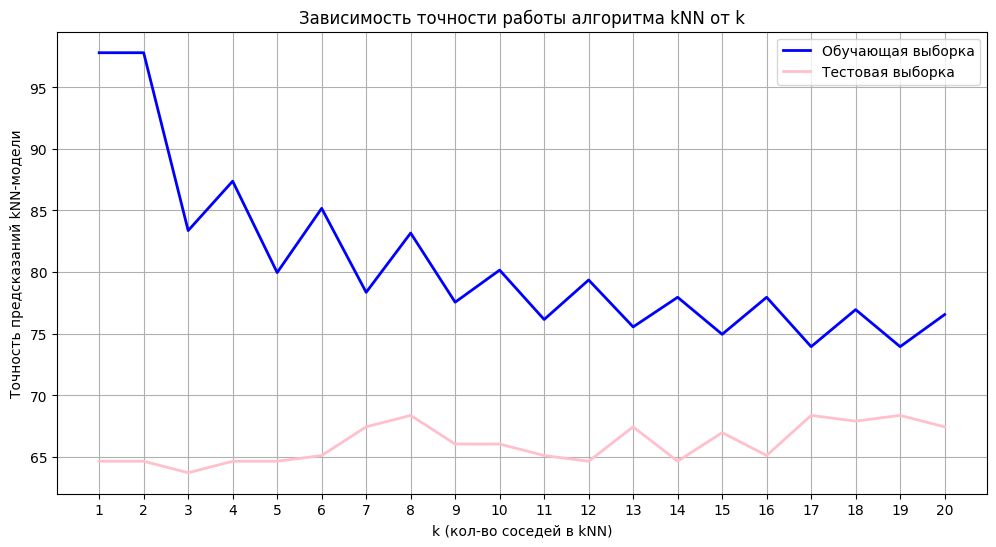

Лучшее для тестовой выборки k = 8 с точностью 68.37%


In [31]:
train_scores = []
test_scores = []

k_values = np.arange(1, 21)

for k in k_values:
    y_train_pred = model_Knn(X_train_stand_scaled, X_train_stand_scaled, k)
    train_acc = accuracy(y_train, y_train_pred)
    train_scores.append(train_acc)

    y_test_pred = model_Knn(X_test_stand_scaled, X_train_stand_scaled, k)
    test_acc = accuracy(y_test, y_test_pred)
    test_scores.append(test_acc)

plt.figure(figsize = (12, 6))
plt.title('Зависимость точности работы алгоритма kNN от k')
plt.plot(k_values, train_scores, label = 'Обучающая выборка', linewidth = 2, color = 'blue')
plt.plot(k_values, test_scores, label = 'Тестовая выборка', linewidth = 2, color = 'pink')

plt.xlabel('k (кол-во соседей в kNN)')
plt.xticks(k_values)

plt.ylabel('Точность предсказаний kNN-модели')

plt.legend()
plt.grid(True)
plt.show()

best_k = k_values[np.argmax(test_scores)]
best_acc = max(test_scores)
print(f"Лучшее для тестовой выборки k = {best_k} с точностью {best_acc:.2f}%")

**Вывод:** $$\newline$$
Расммотрим ОБУЧАЮЩУЮ ВЫБОРКУ и ТРЕНИРОВОЧНУЮ ВЫБОРКИ:
* k $\in [1, 10]$ переобучение: (цитата ИИ: "модель выучила конкретный шум", но не уловила закономерности)
* идеально точные ответы на обучающих данных, а на тестовых данных около $\leq$ 80% маловато - если бы мы обучали беспилотный автомобиль и он бы всего лишь в 80% процентах случаев распознавал красный/зелёный цвет светофора, было бы не очень - много было бы аварий потенциальных.
* k $\in [5, 20]$ наблюдается недообучение (когда модель ошибается и на тестовых и на обучающих данных достаточно сильно)
* k = 4 это оптимальное значение "золотая середина" для данных "Titanic": С одной стороны, разница между предсказаниями модели на тестовых и обучающих данных минимальна (среди всех таких разниц на графике), с другой стороны, точность предсказаний на тестовой выборке достигает своего максимума = 79% (Это как раз что-то около того, что мы получили в ручной if-else модели, там было 72%)

# 4. Сравним качество KNN с логистической регрессией

In [36]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

lr_model = LogisticRegression()
# обычаем на данных со стандартизацией
lr_model.fit(X_train_standard, y_train)
y_pred = lr_model.predict(X_test_standard)
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy * 100:.2f}%")

Accuracy: 70.70%


Логистическая регрессия победила KNN даже с лучшим гиперпараметром:
- лог регресссия: 70.7 % точность
- KNN с лучшим гиперпараметро k: 68 % точность

НО лог регрессия не победила ручную модель (if-else), у к-рой было 72.09% точность
поскольку датасет слишком маленький и я сильно часто обращалась к построенным графикам, то, конечно, рукописная модель с if-else победила